# Mice Liver Ã¢â‚¬â€ Spatiotemporal SIFT
Preprocessing follows nitzanlab notebook 1; SIFT kernel follows notebook 2 (spatial genes).

In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import scipy.sparse as sp
import matplotlib.pyplot as plt
import crisp
import seaborn as sns


In [2]:
# --- Global font settings (consistent, larger, bold titles) ---
plt.rcParams.update({
    "font.size": 18,
    "axes.titlesize": 24,
    "axes.titleweight": "bold",
    "axes.labelsize": 18,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.fontsize": 16,
    "legend.title_fontsize": 17,
    "figure.titlesize": 29,
    "figure.titleweight": "bold",
})


In [3]:
FIGURES_DIR = "../mice_liver_figures2_RBF_labels_HVG"
os.makedirs(FIGURES_DIR, exist_ok=True)

In [4]:
DATA_DIR = "../data"
N_OBS    = 500   # cells per replicate file (250 per A/B)

# 15 known zonated genes Ã¢â‚¬â€ used as SIFT spatial kernel (nitzanlab notebook 2)
SPATIAL_GENES = [
    "glul", "ass1", "asl", "cyp2f2", "cyp1a2", "pck1",
    "cyp2e1", "cdh2", "cdh1", "cyp7a1", "acly", "alb",
    "oat", "aldob", "cps1",
]
TEMPORAL_GENES = ["arntl", "clock", "npas2", "nr1d1", "nr1d2", "per1", "per2", "cry1", "cry2", "dbp", "tef", "hlf",
               "elovl3", "rora", "rorc"]

l_temporal = ["arntl", "clock", "npas2", "nr1d1", "nr1d2", "per1", "per2", "cry1", "cry2", "dbp", "tef", "hlf",
               "elovl3", "rora", "rorc"]
l_spatial= ["glul", "ass1","asl","cyp2f2","cyp1a2","pck1","cyp2e1", "cdh2","cdh1","cyp7a1","acly", "alb", "oat",
             "aldob", "cps1"]

## 1. Load data

In [5]:
def cr_layer_read(path):
    mat = pd.read_csv(path, delimiter=",", header=None).to_numpy()
    return mat.argmax(axis=1), mat          # hard label, soft matrix

def read_sample(path, layer_path, ZT="0", replicate="A", n_obs=250):
    adata = sc.read_csv(path, delimiter="\t").T
    adata.var_names_make_unique(); adata.obs_names_make_unique()
    adata.obs["ZT"]        = ZT
    adata.obs["replicate"] = replicate
    hard, soft = cr_layer_read(layer_path)
    adata.obs["layer"]        = hard
    adata.obsm["layer_probs"] = soft
    sc.pp.subsample(adata, n_obs=n_obs, random_state=123)
    return adata

def read_liver_data(n_obs=500):
    n = int(n_obs / 2)
    files = [
        (f"{DATA_DIR}/GSM4308343_UMI_tab_ZT00A.txt/GSM4308343_UMI_tab_ZT00A.txt", f"{DATA_DIR}/ZT00A_reco.txt", "0",  "A"),
        (f"{DATA_DIR}/GSM4308344_UMI_tab_ZT00B.txt/GSM4308344_UMI_tab_ZT00B.txt", f"{DATA_DIR}/ZT00B_reco.txt", "0",  "B"),
        (f"{DATA_DIR}/GSM4308346_UMI_tab_ZT06A.txt/GSM4308346_UMI_tab_ZT06A.txt", f"{DATA_DIR}/ZT06A_reco.txt", "6",  "A"),
        (f"{DATA_DIR}/GSM4308347_UMI_tab_ZT06B.txt/GSM4308347_UMI_tab_ZT06B.txt", f"{DATA_DIR}/ZT06B_reco.txt", "6",  "B"),
        (f"{DATA_DIR}/GSM4308348_UMI_tab_ZT12A.txt/GSM4308348_UMI_tab_ZT12A.txt", f"{DATA_DIR}/ZT12A_reco.txt", "12", "A"),
        (f"{DATA_DIR}/GSM4308349_UMI_tab_ZT12B.txt/GSM4308349_UMI_tab_ZT12B.txt", f"{DATA_DIR}/ZT12B_reco.txt", "12", "B"),
        (f"{DATA_DIR}/GSM4308351_UMI_tab_ZT18A.txt/GSM4308351_UMI_tab_ZT18A.txt", f"{DATA_DIR}/ZT18A_reco.txt", "18", "A"),
        (f"{DATA_DIR}/GSM4308352_UMI_tab_ZT18B.txt/GSM4308352_UMI_tab_ZT18B.txt", f"{DATA_DIR}/ZT18B_reco.txt", "18", "B"),
    ]
    adatas = []
    for path, lpath, zt, rep in files:
        a = read_sample(path, lpath, ZT=zt, replicate=rep, n_obs=n)
        a.var_names_make_unique(); a.obs_names_make_unique()
        adatas.append(a)
    adata = ad.concat(adatas)
    adata.var_names_make_unique(); adata.obs_names_make_unique()
    return adata


In [6]:
adata = read_liver_data(N_OBS)
print(adata)


/cs/labs/mornitzan/jeremies/anaconda3/envs/interactions_env_qp_gpu/lib/python3.11/site-packages/anndata/_core/anndata.py:1796: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/cs/labs/mornitzan/jeremies/anaconda3/envs/interactions_env_qp_gpu/lib/python3.11/site-packages/anndata/_core/anndata.py:1798: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/cs/labs/mornitzan/jeremies/anaconda3/envs/interactions_env_qp_gpu/lib/python3.11/site-packages/anndata/_core/anndata.py:1796: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/cs/labs/mornitzan/jeremies/anaconda3/envs/interactions_env_qp_gpu/lib/python3.11/site-packages/anndata/_core/anndata.py:1798: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_

AnnData object with n_obs × n_vars = 2000 × 14812
    obs: 'ZT', 'replicate', 'layer'
    obsm: 'layer_probs'


/cs/labs/mornitzan/jeremies/anaconda3/envs/interactions_env_qp_gpu/lib/python3.11/site-packages/anndata/_core/anndata.py:1796: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/cs/labs/mornitzan/jeremies/anaconda3/envs/interactions_env_qp_gpu/lib/python3.11/site-packages/anndata/_core/anndata.py:1798: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


## 2. Preprocess

In [7]:
# quality filters

sc.pp.filter_genes(adata, min_cells=5)
sc.pp.filter_cells(adata, min_genes=500)

# mark MT / Mup genes
adata.var["mt"]  = adata.var_names.str.startswith("mt-")
adata.var["mup"] = adata.var_names.str.startswith("mup")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "mup"], inplace=True)
adata = adata[adata.obs["pct_counts_mt"] < 30].copy()

# store raw counts before normalization
adata.layers["counts"] = adata.X.copy()

# normalize by non-MT / non-Mup gene sum (nitzanlab)
non_mup_mt = (~adata.var["mt"]) & (~adata.var["mup"])
X = adata.X.toarray() if sp.issparse(adata.X) else np.array(adata.X)
denom = X[:, non_mup_mt].sum(axis=1, keepdims=True)
adata.X = X / denom

adata.X = np.log2(adata.X + 1e-4) - np.log2(11e-5)
print(f"before removing MT genes: {adata.n_obs} cells x {adata.n_vars} genes")

# remove MT genes entirely (version without MT genes)
adata = adata[:, ~adata.var["mt"]].copy()
print(f"After removing MT genes: {adata.n_obs} cells x {adata.n_vars} genes")

# keep only highly variable genes -- force the SIFT marker genes (spatial + temporal) to stay
# in even if they don't make the HVG cut, since compute_projection_similarity needs all of them
N_HVG = 3000
sc.pp.highly_variable_genes(adata, n_top_genes=N_HVG)
marker_genes = [g for g in SPATIAL_GENES + TEMPORAL_GENES if g in adata.var_names]
adata.var.loc[marker_genes, "highly_variable"] = True
adata = adata[:, adata.var["highly_variable"]].copy()
print(f"After HVG selection: {adata.n_obs} cells x {adata.n_vars} genes "
      f"(top {N_HVG} HVGs + {len(marker_genes)} SIFT marker genes)")

import copy
orig_adata = copy.deepcopy(adata.copy())
print(f"After preprocessing: {adata.n_obs} cells x {adata.n_vars} genes")
adata.obs["ZT_int"] = adata.obs["ZT"].astype(int)

before removing MT genes: 1909 cells x 10283 genes
After removing MT genes: 1909 cells x 10270 genes


/cs/labs/mornitzan/jeremies/anaconda3/envs/interactions_env_qp_gpu/lib/python3.11/site-packages/scanpy/preprocessing/_highly_variable_genes.py:336: RuntimeWarning: invalid value encountered in log
  dispersion = np.log(dispersion)


After HVG selection: 1909 cells x 3009 genes (top 3000 HVGs + 30 SIFT marker genes)
After preprocessing: 1909 cells x 3009 genes


## 3. PCA + UMAP

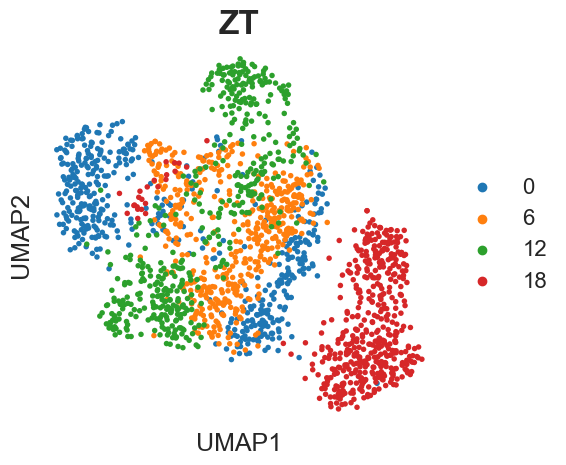

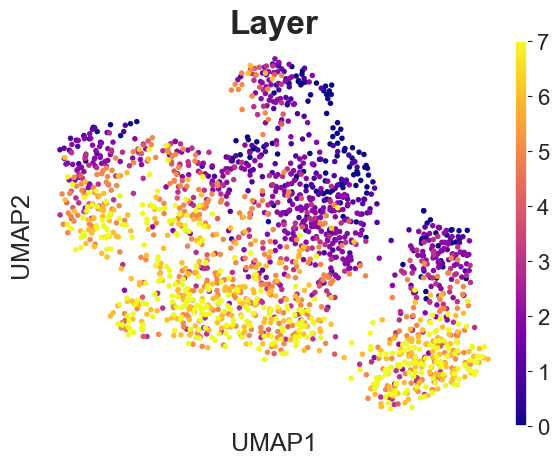

In [8]:
sc.pp.pca(adata)
sc.pp.neighbors(adata, use_rep="X_pca")
sc.tl.umap(adata)

adata.obs["ZT_str"] = pd.Categorical(adata.obs["ZT_int"].astype(str), categories=["0", "6", "12", "18"], ordered=True)
# layer kept as float so sc.pl.umap uses a continuous gradient
adata.obs["layer"] = adata.obs["layer"].astype(float)



fig, ax = plt.subplots(figsize=(6, 5))
ax.set_facecolor("white")
fig.patch.set_facecolor("white")
sc.pl.umap(adata, color="ZT_str", ax=ax, show=False, title="ZT",
         palette=["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"])
for spine in ax.spines.values():
  spine.set_visible(True)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "umap_ZT.png"), dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
ax.set_facecolor("white")
fig.patch.set_facecolor("white")
sc.pl.umap(adata, color="layer", ax=ax, show=False, title="Layer",
         color_map="plasma")
for spine in ax.spines.values():
  spine.set_visible(True)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "umap_layer.png"), dpi=150, bbox_inches="tight", facecolor="white")
plt.show()





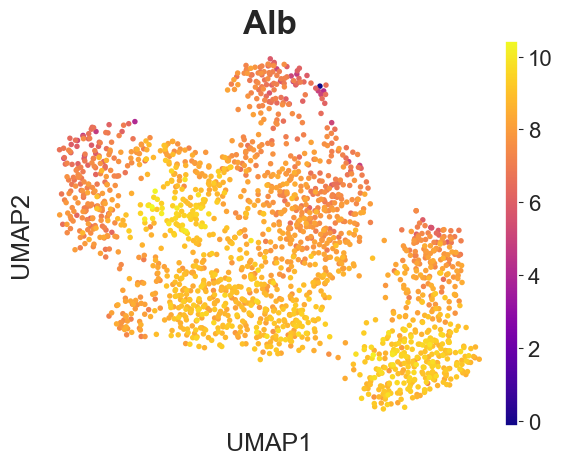

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.set_facecolor("white")
fig.patch.set_facecolor("white")
sc.pl.umap(adata, color="alb", ax=ax, show=False, title="Alb",
         color_map="plasma")
for spine in ax.spines.values():
  spine.set_visible(True)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "umap_alb.png"), dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

## 4. SIFT Ã¢â‚¬â€ spatial genes kernel

In [10]:


bdata = adata.copy()

# spatial kernel: expression of known zonated genes (nitzanlab notebook 2)
spatial_present = [g for g in SPATIAL_GENES if g in bdata.var_names]
print(f"Spatial genes found: {len(spatial_present)}/{len(SPATIAL_GENES)}")
temporal_present = [g for g in TEMPORAL_GENES if g in bdata.var_names]
print(f"Temporal genes found: {len(temporal_present)}/{len(TEMPORAL_GENES)}")
X_sp = bdata[:, spatial_present].X
bdata.obsm["spatial_genes"] = X_sp.toarray() if sp.issparse(X_sp) else np.array(X_sp)
X_tp = bdata[:, temporal_present].X
bdata.obsm["temporal_genes"] = X_tp.toarray() if sp.issparse(X_tp) else np.array(X_tp)
# ZT as circular signal
crisp.encode_circular(bdata, "ZT_int")

# signal_A = spatial zonation,  signal_B = circadian ZT
global_score = crisp.compute_projection_similarity(
    bdata,
    signal_A="layer",
    signal_B="circular_ZT_int",
    metric_A="rbf",
    metric_B="rbf",
    store_projections=True,
)
print(f"Global score: {global_score:.4f}")


Spatial genes found: 15/15
Temporal genes found: 15/15
[timing] PCA + neighbors:   0.59s
[crisp] RBF length_scale for 'layer' (median * 0.5): 0.007478
0.00747806535236164
[timing] SIFT signal A:     1.74s
[crisp] RBF length_scale for 'circular_ZT_int' (median * 0.5): 14.310830
14.310829992902931
[timing] SIFT signal B:     4.04s
Global score: 0.9834


## 5. UMAP of cell score

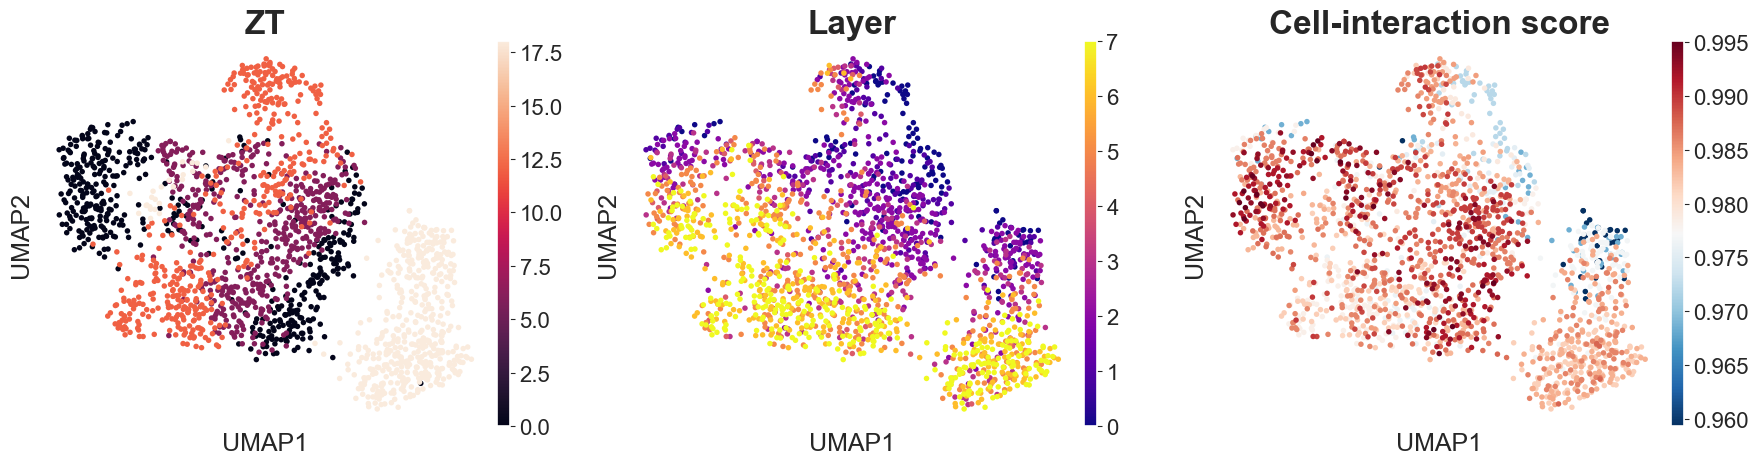

In [11]:
bdata.obsm["X_umap"] = adata.obsm["X_umap"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sc.pl.umap(bdata, color="ZT_int",        ax=axes[0], show=False, title="ZT")
sc.pl.umap(bdata, color="layer",         ax=axes[1], show=False, title="Layer", color_map="plasma")
sc.pl.umap(bdata, color="proj_pearson_cell", ax=axes[2], show=False,
           title="Cell-interaction score", cmap="RdBu_r")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "umap_cell_scores.png"), dpi=150, bbox_inches="tight")
plt.show()


In [12]:
try:
    from sift import SiFT
except ImportError:
    from sift._sift import SiFT

from scipy.spatial.distance import pdist


def plot_sift_kernel(
    adata,
    signal_key,
    groupby,
    n_neighbors=15,
    metric="knn",
    kernel_params=None,
    subset_obs=None,
    figsize=(7, 6),
    cmap="Blues",
    ax=None,
    save_path=None,
):
    bdata = adata.copy()
    kparams = dict(kernel_params or {})
    median_factor = kparams.pop("median_factor", 0.5)

    if subset_obs is not None:
        for col, val in subset_obs.items():
            bdata = bdata[bdata.obs[col] == val].copy()
        print(f"Subset: {bdata.n_obs} cells")

    try:
        sort_idx = np.argsort(bdata.obs[groupby].values.astype(float))
    except (ValueError, TypeError):
        sort_idx = np.argsort(bdata.obs[groupby].astype(str).values)
    bdata = bdata[sort_idx].copy()

    # SiFT indexes the kernel signal as obj[:, None], which fails on a pandas Series.
    # Mirror crisp._ensure_obsm: move an obs column into obsm as a normalized 2D
    # array so SiFT gets a numpy array and length_scale matches crisp.
    if metric != "knn" and signal_key not in bdata.obsm and signal_key in bdata.obs:
        _sig = bdata.obs[signal_key].values.astype(float)
        _norm = np.linalg.norm(_sig)
        bdata.obsm[signal_key] = (_sig / _norm if _norm > 0 else _sig).reshape(-1, 1)

    # Median heuristic for RBF bandwidth
    if metric != "knn" and "length_scale" not in kparams:
        signal = bdata.obsm[signal_key]
        if hasattr(signal, "toarray"):
            signal = signal.toarray()
        signal = np.asarray(signal, dtype=float)   # Series -> ndarray FIRST
        if signal.ndim == 1:
            signal = signal.reshape(-1, 1)
        dists = pdist(signal)
        dists = dists[dists > 0]
        kparams["length_scale"] = median_factor * (float(np.median(dists)) if len(dists) > 0 else 1.0)
        print(f"[plot_sift_kernel] RBF length_scale (median * {median_factor}): {kparams['length_scale']:.6f}")
    if "length_scale" in kparams:
        print(kparams["length_scale"])

    sft = SiFT(bdata, kernel_key=signal_key, metric=metric, n_neighbors=n_neighbors, kernel_params=kparams)

    if metric == "knn":
        raw_k = sft._kernel(**sft._kernel_containers)
        K = raw_k.toarray() if hasattr(raw_k, "toarray") else np.array(raw_k)
    else:
        raw_k = sft._kernel(materialize=True, **sft._kernel_containers)
        K = raw_k.cpu().numpy() if hasattr(raw_k, "cpu") else np.array(raw_k)

    K = K.astype(float)

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    im = ax.imshow(K, cmap=cmap, aspect="auto", interpolation="none", vmin=0)
    plt.colorbar(im, ax=ax, shrink=0.8, label="Kernel weight")

    labels = bdata.obs[groupby].values
    try:
        labels = labels.astype(float)
    except (ValueError, TypeError):
        pass
    unique_labels, counts = np.unique(labels, return_counts=True)
    midpoints = np.cumsum(counts) - counts / 2
    boundaries = np.cumsum(counts)[:-1]

    for b in boundaries:
        ax.axvline(b - 0.5, color="red", linewidth=0.8, alpha=0.5)
        ax.axhline(b - 0.5, color="red", linewidth=0.8, alpha=0.5)

    ax.set_xticks(midpoints)
    ax.set_xticklabels(unique_labels, rotation=45, ha="right", fontsize=16)
    ax.set_yticks(midpoints)
    ax.set_yticklabels(unique_labels, fontsize=16)
    ax.set_title(
        f"SIFT kernel  |  signal: '{signal_key}' ({metric})\nsorted by '{groupby}'  "
        f"(n={bdata.n_obs})",
        fontsize=24,
    )

    if save_path:
        fig.savefig(save_path, bbox_inches="tight", dpi=150)
    plt.tight_layout()
    return ax

[plot_sift_kernel] RBF length_scale (median * 0.5): 0.007478
0.00747806535236164
[plot_sift_kernel] RBF length_scale (median * 0.5): 14.310830
14.310829992902931


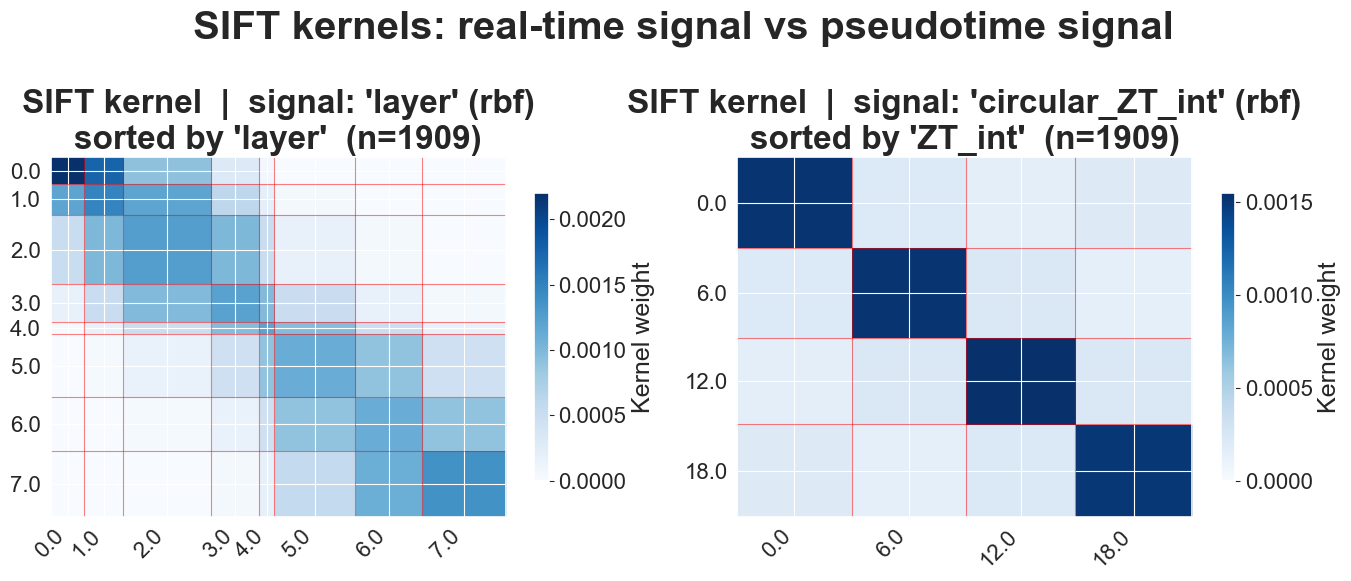

In [13]:
LENGTH_SCALE = None  # set to a float to override the median heuristic, e.g. 0.007
_kp = {"length_scale": LENGTH_SCALE} if LENGTH_SCALE is not None else None

# Both kernels side by side, full dataset, sorted by time_int
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_sift_kernel(bdata, signal_key="layer",   groupby="layer", metric="rbf", kernel_params=_kp, ax=axes[0])
LENGTH_SCALE = None  # set to a float to override the median heuristic, e.g. 0.007
_kp = {"length_scale": LENGTH_SCALE} if LENGTH_SCALE is not None else None
plot_sift_kernel(bdata, signal_key="circular_ZT_int", groupby="ZT_int", metric="rbf", kernel_params=_kp, ax=axes[1])
plt.suptitle("SIFT kernels: real-time signal vs pseudotime signal", fontsize=29)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "kernel_comparison.png"), bbox_inches="tight", dpi=150)
plt.show()

In [14]:
# Inspect actual kernel values: first row (circular vs diagonal check)
from scipy.spatial.distance import pdist as _pdist
import pandas as _pd

_signal_key, _groupby, _metric = "circular_ZT_int", "ZT_int", "rbf"
_kdata = bdata.copy()
try:
    _si = np.argsort(_kdata.obs[_groupby].values.astype(float))
except (ValueError, TypeError):
    _si = np.argsort(_kdata.obs[_groupby].astype(str).values)
_kdata = _kdata[_si].copy()
_kp = {}
if _signal_key not in _kdata.obsm and _signal_key in _kdata.obs:
    _s = _kdata.obs[_signal_key].values.astype(float)
    _n = np.linalg.norm(_s)
    _kdata.obsm[_signal_key] = (_s / _n if _n > 0 else _s).reshape(-1, 1)
_sig = np.asarray(_kdata.obsm[_signal_key], dtype=float)
if _sig.ndim == 1:
    _sig = _sig.reshape(-1, 1)
_dd = _pdist(_sig); _dd = _dd[_dd > 0]
_kp["length_scale"] = 0.5 * (float(np.median(_dd)) if len(_dd) else 1.0)
print("length_scale:", _kp["length_scale"])

_sft = SiFT(_kdata, kernel_key=_signal_key, metric=_metric, n_neighbors=15, kernel_params=_kp)
_raw = _sft._kernel(materialize=True, **_sft._kernel_containers)
_K = _raw.cpu().numpy() if hasattr(_raw, "cpu") else np.array(_raw)
_K = _K.astype(float)
_zt = _kdata.obs[_groupby].values

np.set_printoptions(precision=5, suppress=True, linewidth=160)
print("Kernel shape:", _K.shape, " | cell 0 is at ZT =", _zt[0])
print("\nK[0], first 25 entries:")
print(_K[0, :25])
print("\nK[0] averaged per ZT group (diag ZT largest; wrap-around ZTs = circular):")
print(_pd.Series(_K[0], index=_zt).groupby(level=0).mean())

length_scale: 14.310829992902931
Kernel shape: (1909, 1909)  | cell 0 is at ZT = 0

K[0], first 25 entries:
[0.00152 0.00152 0.00152 0.00152 0.00152 0.00152 0.00152 0.00152 0.00152 0.00152 0.00152 0.00152 0.00152 0.00152 0.00152 0.00152 0.00152 0.00152 0.00152
 0.00152 0.00152 0.00152 0.00152 0.00152 0.00152]

K[0] averaged per ZT group (diag ZT largest; wrap-around ZTs = circular):
0     0.001517
6     0.000210
12    0.000153
18    0.000205
dtype: float64


In [15]:
# sc.pp.filter_genes_dispersion(bdata, n_top_genes=500)


## 6. Gene ranking by category


[gene-interaction score] Z+R (164 found, 183 not found)
Gene                 Rank       Score     
------------------------------------------
ttr                  5          0.0303
pck1                 25         0.0093
thrsp                29         0.0066
cdo1                 40         0.0050
hspa5                51         0.0041
c9                   60         0.0034
vtn                  66         0.0027
ddt                  68         0.0025
elovl5               81         0.0021
hsd11b1              97         0.0015
fasn                 99         0.0014
rnase4               104        0.0013
ppib                 122        0.0009
ly6e                 135        0.0008
gabarap              141        0.0008
dnaja1               154        0.0007
hsp90aa1             157        0.0007
slc2a2               160        0.0006
gm10076              177        0.0005
etnk2                181        0.0005
keg1                 184        0.0005
lman1                192        0.0004

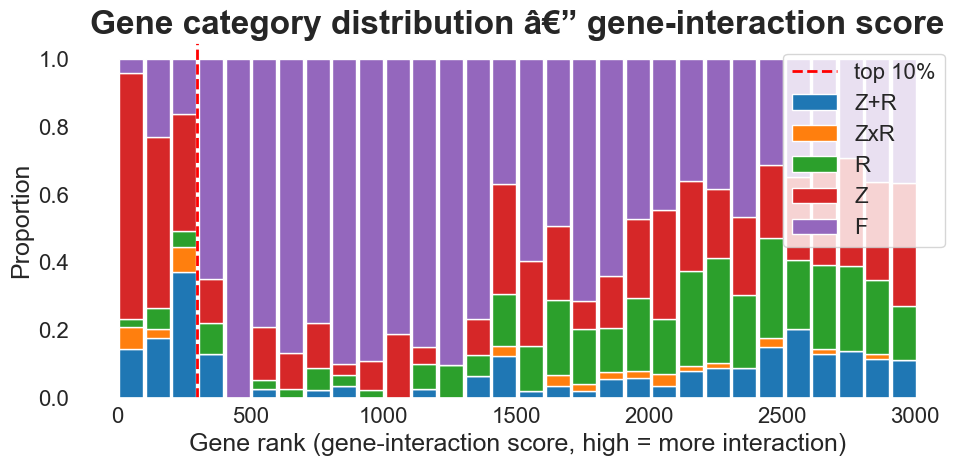

In [16]:
# proj_pearson_gene_contrib is written automatically by compute_projection_similarity.
bdata.var["cont_score"] = bdata.var["proj_pearson_gene_contrib"].values

csv_files = ['Z+R.csv', 'ZxR.csv', 'R.csv', 'Z.csv', 'F.csv']
n_bins = 30
score_key, score_title = 'cont_score', 'gene-interaction score'

gene_scores = bdata.var[score_key].dropna().sort_values(ascending=False)
n_genes_cs  = len(gene_scores)
lookup_cs   = {g.lower(): (rank + 1, g, v)
               for rank, (g, v) in enumerate(gene_scores.items())}

bins        = np.linspace(1, n_genes_cs, n_bins + 1)
bin_centers = (bins[:-1] + bins[1:]) / 2
all_labels, all_ranks = [], {}

for csv_file in csv_files:
    label = csv_file.replace('.csv', '')
    genes = pd.read_csv(csv_file).iloc[:, 0].str.lower().tolist()

    found, not_found = [], []
    for gene in genes:
        if gene in lookup_cs:
            rank, orig, score = lookup_cs[gene]
            found.append((orig, rank, score))
        else:
            not_found.append(gene)

    found.sort(key=lambda x: x[1])
    print(f'\n[{score_title}] {label} ({len(found)} found, {len(not_found)} not found)')
    print(f'{"Gene":<20} {"Rank":<10} {"Score":<10}')
    print('-' * 42)
    for orig, rank, score in found:
        print(f'{orig:<20} {rank:<10} {score:.4f}')

    all_labels.append(label)
    counts, _ = np.histogram([r for _, r, _ in found], bins=bins)
    all_ranks[label] = counts

total = sum(all_ranks[l] for l in all_labels).astype(float)
total[total == 0] = np.nan

fig, ax = plt.subplots(figsize=(10, 5))
bottom = np.zeros(n_bins)
for label in all_labels:
    prop = np.nan_to_num(all_ranks[label] / total)
    ax.bar(bin_centers, prop, width=(bins[1] - bins[0]) * 0.9,
           bottom=bottom, label=label)
    bottom += prop

ax.axvline(n_genes_cs * 0.1, color='red', linestyle='--', label='top 10%')
ax.set_xlabel('Gene rank (gene-interaction score, high = more interaction)')
ax.set_ylabel('Proportion')
ax.set_title(f'Gene category distribution â€” {score_title}')
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, f'gene_ranking_{score_key}.png'),
            dpi=150, bbox_inches='tight')
plt.show()


In [17]:
# Top 50 genes by cont_score with their category
gene_cat_top = {}
for label in reversed(['ZxR', 'Z+R', 'Z', 'R', 'F']):
    try:
        for g in pd.read_csv(f'{label}.csv').iloc[:, 0].str.lower():
            gene_cat_top[g] = label
    except FileNotFoundError:
        pass

top50 = (
    bdata.var[['cont_score']]
    .copy()
    .assign(category=[
        gene_cat_top.get(g.lower(), 'other') for g in bdata.var_names
    ])
    .sort_values('cont_score', ascending=False)
    .head(50)
)

print(f'Top 50 genes by contribution score\n')
print(f'{"Rank":<6} {"Gene":<20} {"cont_score":<14} {"category"}')
print('-' * 52)
for rank, (gene, row) in enumerate(top50.iterrows(), 1):
    print(f'{rank:<6} {gene:<20} {row["cont_score"]:<14.5f} {row["category"]}')


Top 50 genes by contribution score

Rank   Gene                 cont_score     category
----------------------------------------------------
1      alb                  0.05647        Z
2      fabp1                0.03839        other
3      apoa2                0.03613        Z
4      trf                  0.03474        Z
5      ttr                  0.03032        Z+R
6      scd1                 0.02502        other
7      mgst1                0.02481        Z
8      mup20                0.02362        other
9      apoc3                0.02135        Z
10     gc                   0.02012        Z
11     cyp3a11              0.01940        Z
12     apoa1                0.01766        ZxR
13     hpx                  0.01758        Z
14     cps1                 0.01647        Z
15     aldob                0.01539        ZxR
16     car3                 0.01522        Z
17     apoc4                0.01461        other
18     cat                  0.01435        Z
19     rpl32               

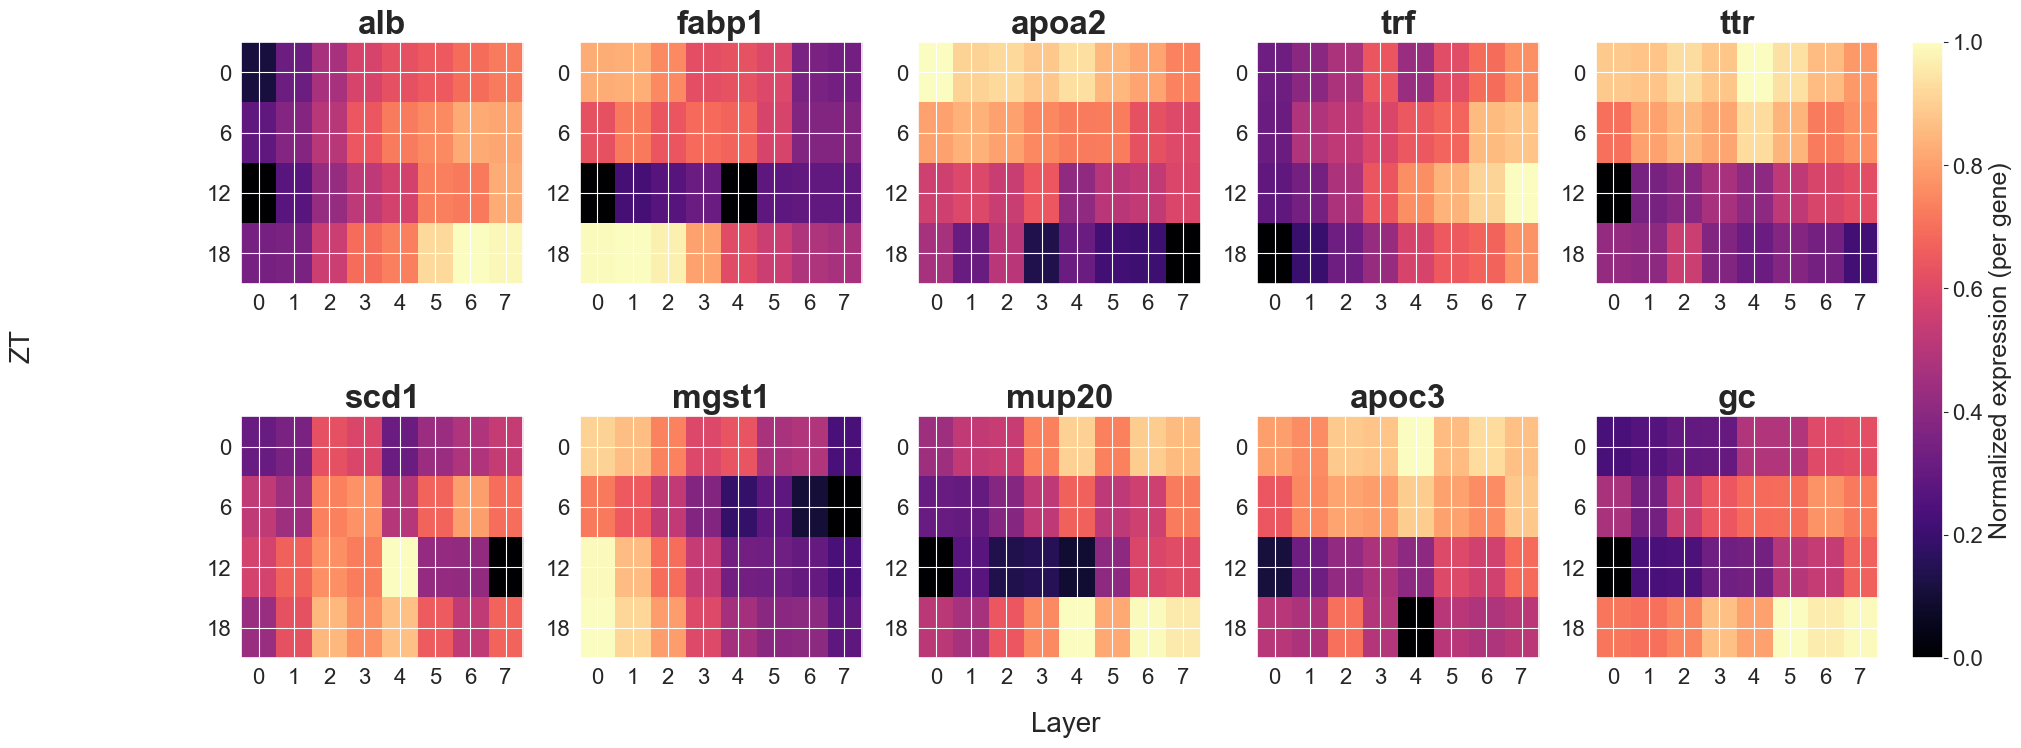

In [30]:
# Expression heatmap (ZT x layer) for top 10 genes by cont_score
# Each gene's ZT x layer mean-expression grid is min-max normalized to [0, 1]
# (per gene) so that all ten panels share one colorbar / color scale.
X_mat_top = bdata.X.toarray() if sp.issparse(bdata.X) else np.array(bdata.X)
var_names_top = list(bdata.var_names)

top10_genes = top50.index[:10].tolist()

fig, axes = plt.subplots(2, 5, figsize=(22, 8), gridspec_kw={'hspace': 0.55})
axes = axes.flatten()

im = None
for ax, gene in zip(axes, top10_genes):
    gene_idx = var_names_top.index(gene)
    df_gene  = bdata.obs[['ZT_int', 'layer']].copy()
    df_gene['expr'] = X_mat_top[:, gene_idx]
    pivot = df_gene.groupby(['ZT_int', 'layer'])['expr'].mean().unstack('layer')

    vals = pivot.values
    vmin, vmax = np.nanmin(vals), np.nanmax(vals)
    norm_vals = (vals - vmin) / (vmax - vmin) if vmax > vmin else np.zeros_like(vals)

    cat = top50.loc[gene, 'category']
    im = ax.imshow(norm_vals, aspect='auto', cmap='magma', vmin=0, vmax=1)
    ax.set_xticks(range(pivot.shape[1]))
    ax.set_xticklabels(range(pivot.shape[1]), fontsize=16)
    ax.set_yticks(range(pivot.shape[0]))
    ax.set_yticklabels(pivot.index, fontsize=16)
    ax.set_title(f'{gene}', fontsize=24, fontweight='bold')

# One shared label per axis for the whole grid instead of per-panel labels
fig.supxlabel('Layer', fontsize=20)
fig.supylabel('ZT', fontsize=20)

fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02, label='Normalized expression (per gene)')
# plt.suptitle('Expression heatmap of top 10 genes by gene-interaction score', fontsize=29, y=1.02)
plt.savefig(os.path.join(FIGURES_DIR, 'cont_score_top10_heatmap.png'),
            dpi=150, bbox_inches='tight')
plt.show()


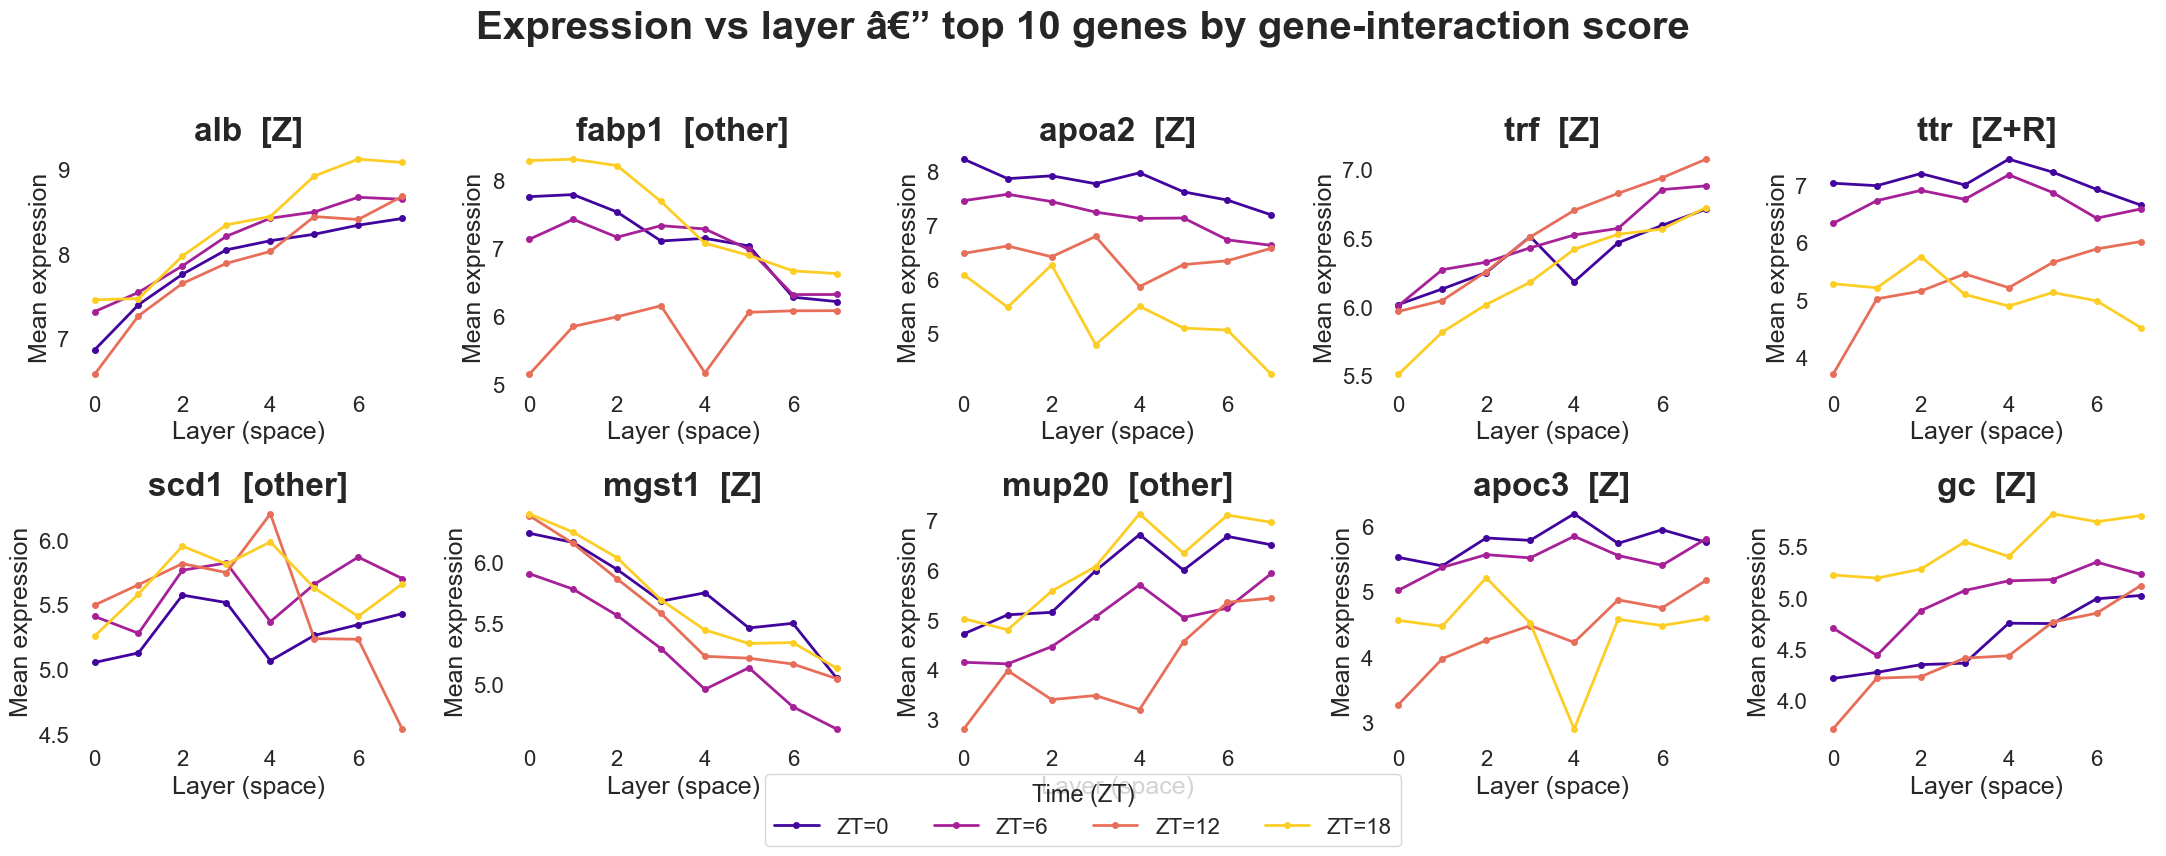

In [19]:
# Expression vs layer, one curve per ZT â€” top 10 genes by cont_score
zt_values  = sorted(bdata.obs['ZT_int'].unique())
zt_palette = plt.cm.plasma(np.linspace(0.1, 0.9, len(zt_values)))

fig, axes = plt.subplots(2, 5, figsize=(22, 8), sharey=False)
axes = axes.flatten()

for ax, gene in zip(axes, top10_genes):
    gene_idx = var_names_top.index(gene)
    df_gene  = bdata.obs[['ZT_int', 'layer']].copy()
    df_gene['expr'] = X_mat_top[:, gene_idx]
    pivot = df_gene.groupby(['ZT_int', 'layer'])['expr'].mean().unstack('layer')

    for zt, color in zip(zt_values, zt_palette):
        if zt in pivot.index:
            ax.plot(pivot.columns, pivot.loc[zt], marker='o', ms=4,
                    color=color, label=f'ZT={zt}')

    cat = top50.loc[gene, 'category']
    ax.set_xlabel('Layer (space)', fontsize=18)
    ax.set_ylabel('Mean expression', fontsize=18)
    ax.set_title(f'{gene}  [{cat}]', fontsize=24, fontweight='bold')
    ax.tick_params(labelsize=16)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title='Time (ZT)', fontsize=16, title_fontsize=17,
           loc='lower center', ncol=len(zt_values), bbox_to_anchor=(0.5, -0.04))

plt.suptitle('Expression vs layer â€” top 10 genes by gene-interaction score', fontsize=29, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'cont_score_top10_layer_curves.png'),
            dpi=150, bbox_inches='tight')
plt.show()


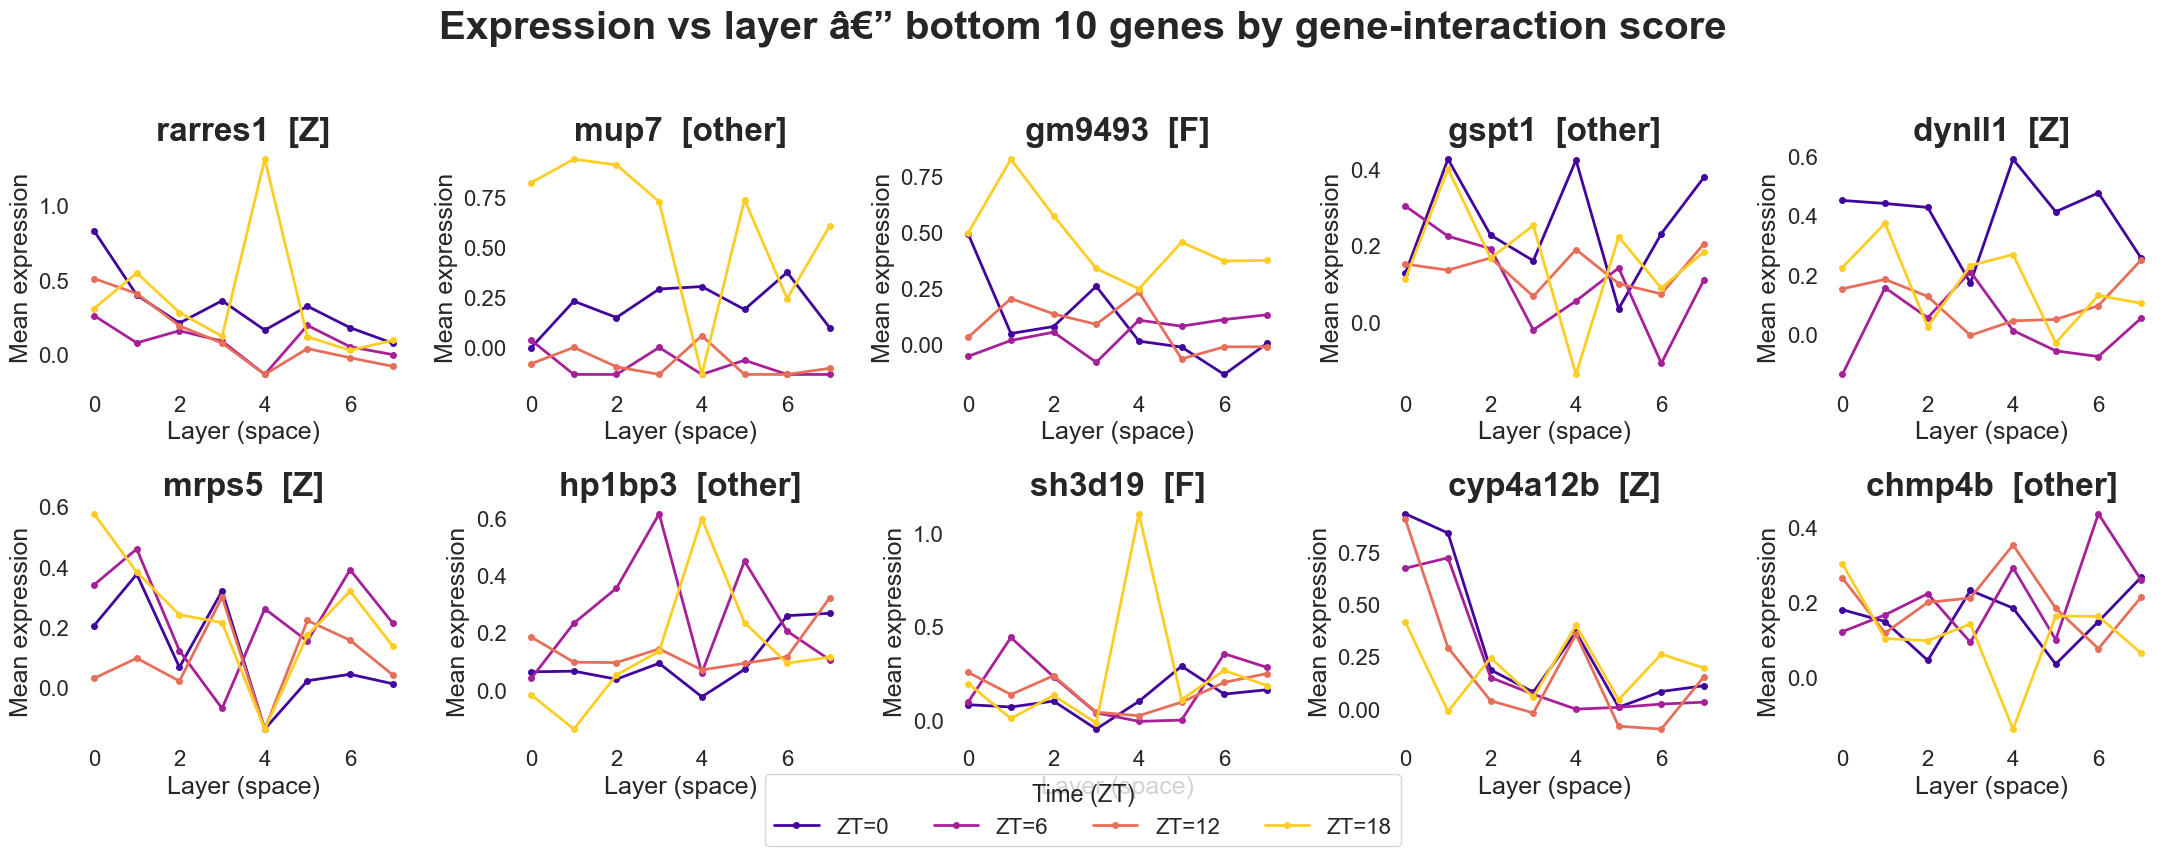

In [20]:
# Same plot for bottom 10 genes by cont_score
bottom10 = (
    bdata.var[['cont_score']]
    .copy()
    .assign(category=[
        gene_cat_top.get(g.lower(), 'other') for g in bdata.var_names
    ])
    .sort_values('cont_score', ascending=True)
    .head(10)
)
bottom10_genes = bottom10.index.tolist()

fig, axes = plt.subplots(2, 5, figsize=(22, 8), sharey=False)
axes = axes.flatten()

for ax, gene in zip(axes, bottom10_genes):
    gene_idx = var_names_top.index(gene)
    df_gene  = bdata.obs[['ZT_int', 'layer']].copy()
    df_gene['expr'] = X_mat_top[:, gene_idx]
    pivot = df_gene.groupby(['ZT_int', 'layer'])['expr'].mean().unstack('layer')

    for zt, color in zip(zt_values, zt_palette):
        if zt in pivot.index:
            ax.plot(pivot.columns, pivot.loc[zt], marker='o', ms=4,
                    color=color, label=f'ZT={zt}')

    cat = bottom10.loc[gene, 'category']
    ax.set_xlabel('Layer (space)', fontsize=18)
    ax.set_ylabel('Mean expression', fontsize=18)
    ax.set_title(f'{gene}  [{cat}]', fontsize=24, fontweight='bold')
    ax.tick_params(labelsize=16)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title='Time (ZT)', fontsize=16, title_fontsize=17,
           loc='lower center', ncol=len(zt_values), bbox_to_anchor=(0.5, -0.04))

plt.suptitle('Expression vs layer â€” bottom 10 genes by gene-interaction score', fontsize=29, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'cont_score_bottom10_layer_curves.png'),
            dpi=150, bbox_inches='tight')
plt.show()


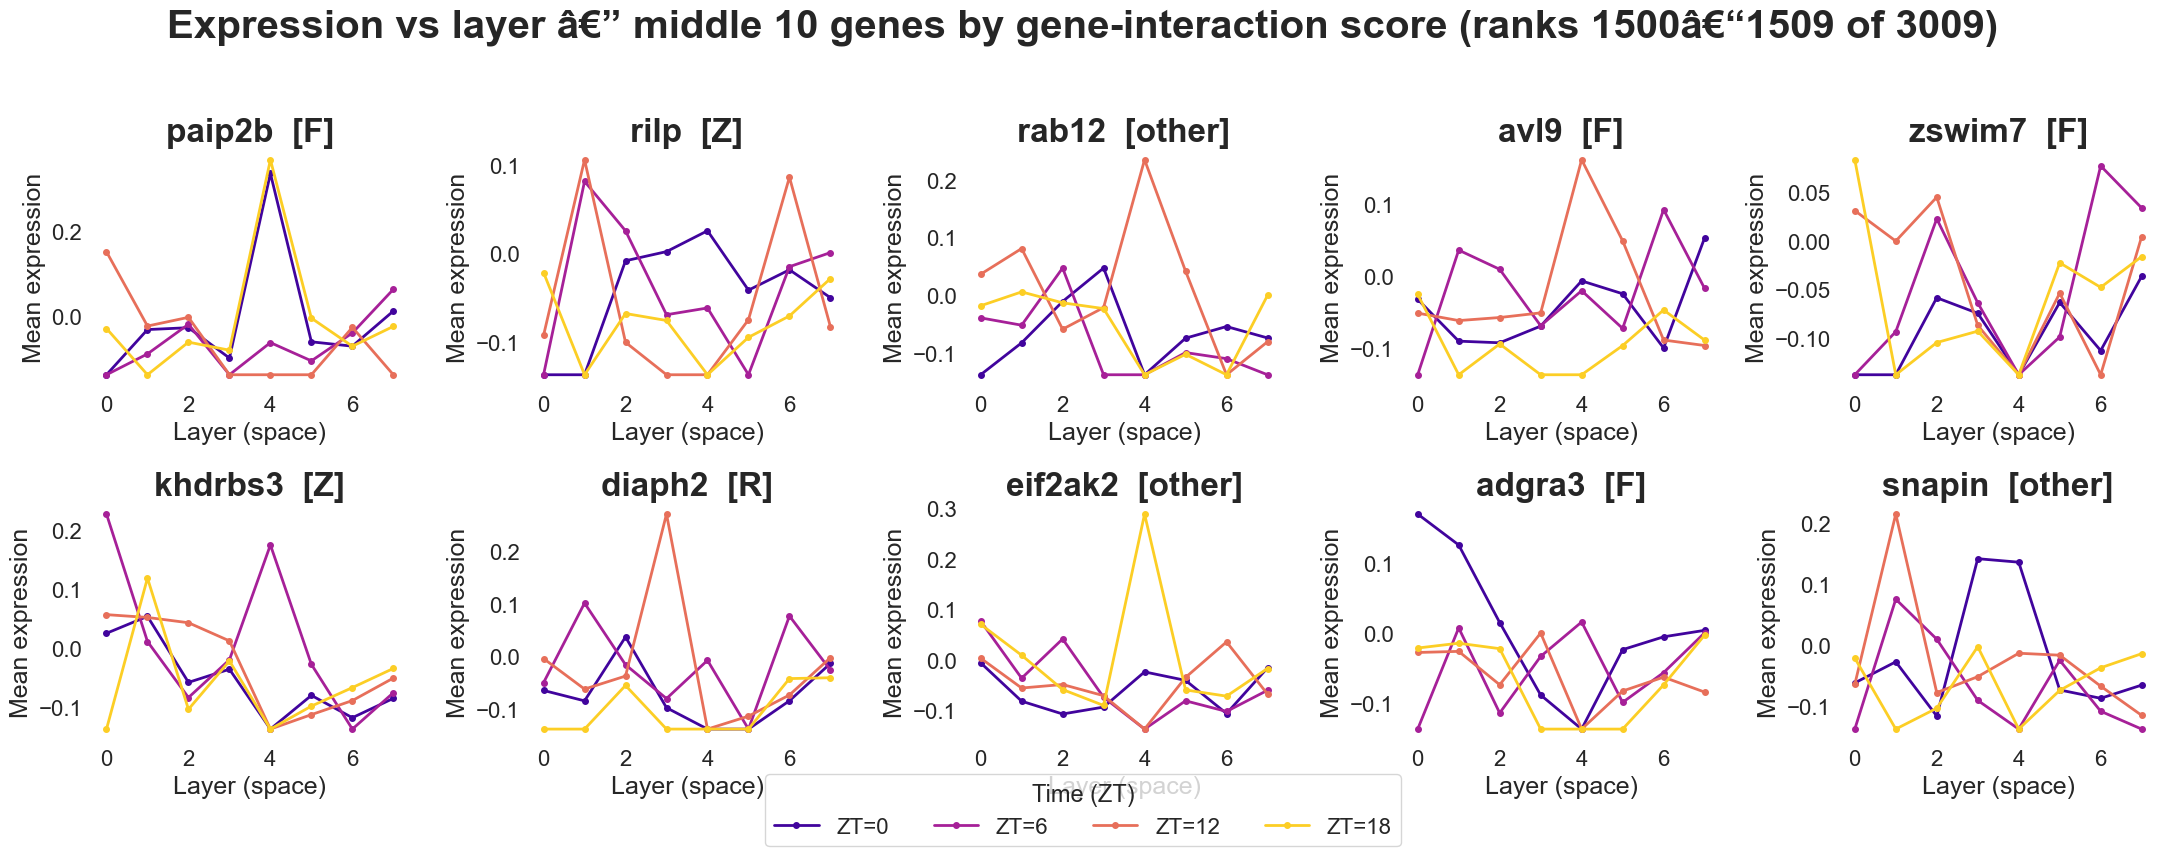

In [21]:
# Same plot for 10 genes at the middle of the cont_score ranking
all_ranked = (
    bdata.var[['cont_score']]
    .copy()
    .assign(category=[
        gene_cat_top.get(g.lower(), 'other') for g in bdata.var_names
    ])
    .dropna(subset=['cont_score'])
    .sort_values('cont_score', ascending=False)
)
mid = len(all_ranked) // 2
mid10 = all_ranked.iloc[mid - 5 : mid + 5]
mid10_genes = mid10.index.tolist()

fig, axes = plt.subplots(2, 5, figsize=(22, 8), sharey=False)
axes = axes.flatten()

for ax, gene in zip(axes, mid10_genes):
    gene_idx = var_names_top.index(gene)
    df_gene  = bdata.obs[['ZT_int', 'layer']].copy()
    df_gene['expr'] = X_mat_top[:, gene_idx]
    pivot = df_gene.groupby(['ZT_int', 'layer'])['expr'].mean().unstack('layer')

    for zt, color in zip(zt_values, zt_palette):
        if zt in pivot.index:
            ax.plot(pivot.columns, pivot.loc[zt], marker='o', ms=4,
                    color=color, label=f'ZT={zt}')

    cat = mid10.loc[gene, 'category']
    ax.set_xlabel('Layer (space)', fontsize=18)
    ax.set_ylabel('Mean expression', fontsize=18)
    ax.set_title(f'{gene}  [{cat}]', fontsize=24, fontweight='bold')
    ax.tick_params(labelsize=16)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title='Time (ZT)', fontsize=16, title_fontsize=17,
           loc='lower center', ncol=len(zt_values), bbox_to_anchor=(0.5, -0.04))

plt.suptitle(
    f'Expression vs layer â€” middle 10 genes by gene-interaction score'
    f' (ranks {mid - 4}â€“{mid + 5} of {len(all_ranked)})',
    fontsize=29, y=1.02,
)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'cont_score_mid10_layer_curves.png'),
            dpi=150, bbox_inches='tight')
plt.show()


/tmp/ipykernel_339222/983157346.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


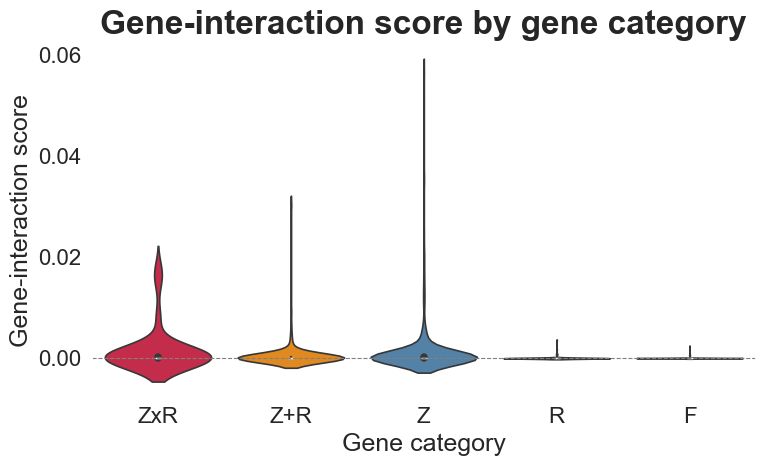

In [22]:
# Violin of cont_score by gene category
cat_order  = ['ZxR', 'Z+R', 'Z', 'R', 'F']
cat_colors = {'ZxR': 'crimson', 'Z+R': 'darkorange', 'Z': 'steelblue',
              'R': 'seagreen',   'F': 'grey'}

gene_cat = {}
for label in reversed(cat_order):  # lower priority first so higher overwrites
    try:
        for g in pd.read_csv(f'{label}.csv').iloc[:, 0].str.lower():
            gene_cat[g] = label
    except FileNotFoundError:
        pass

df_violin = pd.DataFrame({
    'cont_score': bdata.var['cont_score'].values,
    'category':   [gene_cat.get(g.lower(), None) for g in bdata.var_names],
})
df_violin = df_violin[df_violin['category'].notna()]

fig, ax = plt.subplots(figsize=(8, 5))
sns.violinplot(
    data=df_violin, x='category', y='cont_score',
    order=cat_order,
    palette=cat_colors,
    inner='box', linewidth=1.2, ax=ax,
)
ax.axhline(0, color='gray', lw=0.8, ls='--')
ax.set_xlabel('Gene category', fontsize=18)
ax.set_ylabel('Gene-interaction score', fontsize=18)
ax.set_title(
    'Gene-interaction score by gene category',
    fontsize=24,
)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'gene_cont_score_violin.png'),
            dpi=150, bbox_inches='tight')
plt.show()


/tmp/ipykernel_339222/3869512741.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


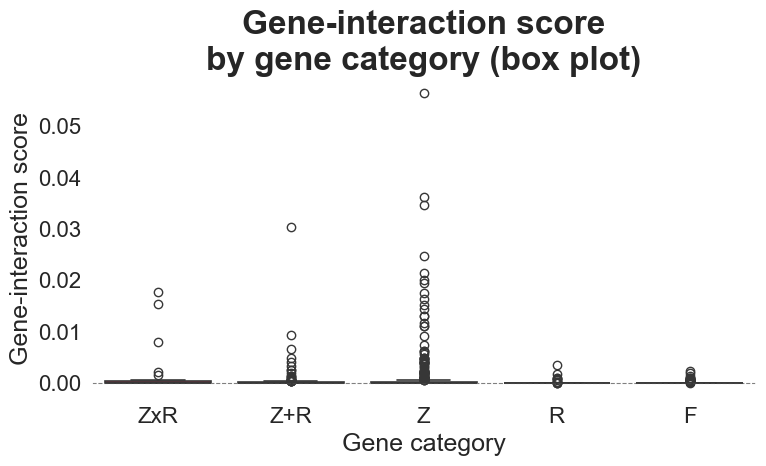

Mean cont_score per category (unfiltered):
category
ZxR    0.001702
Z+R    0.000522
Z      0.001254
R      0.000062
F      0.000065


In [23]:
# Same analysis as above, using a box plot instead of a violin plot
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=df_violin, x='category', y='cont_score',
    order=cat_order,
    palette=cat_colors,
    linewidth=1.2, ax=ax,
)
ax.axhline(0, color='gray', lw=0.8, ls='--')
ax.set_xlabel('Gene category', fontsize=18)
ax.set_ylabel('Gene-interaction score', fontsize=18)
ax.set_title(
    'Gene-interaction score' + chr(10) + 'by gene category (box plot)',
    fontsize=24,
)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'gene_cont_score_box.png'),
            dpi=150, bbox_inches='tight')
plt.show()

means = df_violin.groupby('category')['cont_score'].mean().reindex(cat_order)
print('Mean cont_score per category (unfiltered):')
print(means.to_string())


/tmp/ipykernel_339222/377936872.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_339222/377936872.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


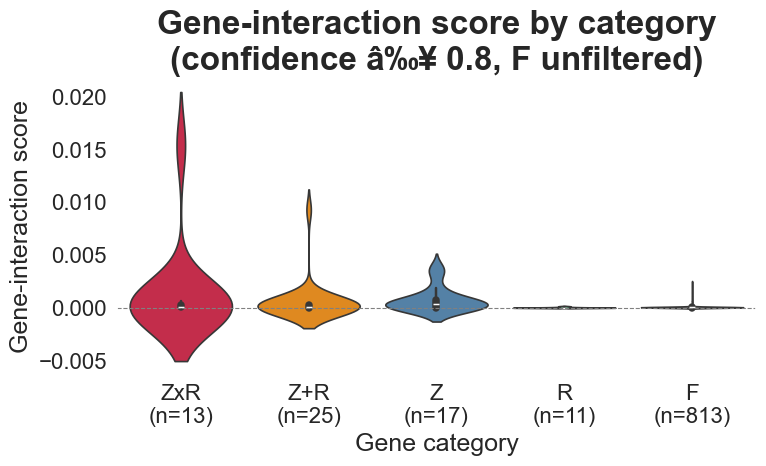


Top 10 genes per category (confidence >= 0.8, ranked by cont_score)

  [ZxR]  (n=10)
  Gene                 cont_score
  --------------------------------
  aldob                0.01539
  upp2                 0.00064
  slc7a2               0.00033
  etnppl               0.00028
  mt1                  0.00024
  hsd17b6              0.00015
  clpx                 0.00010
  nampt                0.00004
  cyp2a5               0.00004
  slc1a2               0.00003

  [Z+R]  (n=10)
  Gene                 cont_score
  --------------------------------
  pck1                 0.00928
  rnase4               0.00126
  hsp90aa1             0.00066
  keg1                 0.00048
  bnip3                0.00041
  ftcd                 0.00034
  lpin2                0.00028
  iqgap2               0.00027
  elovl3               0.00015
  por                  0.00015

  [Z]  (n=10)
  Gene                 cont_score
  --------------------------------
  rgn                  0.00382
  cyp2f2               0

In [24]:
# Same violin, restricted to genes with confidence >= 0.8
CONF_THRESHOLD_VLN = 0.8

score_lookup = {
    g.lower(): v
    for g, v in zip(bdata.var_names, bdata.var['cont_score'].values)
}

rows_conf = []
for label in cat_order:
    df = pd.read_csv(f'{label}.csv')
    if label == 'F':
        df_conf = df  # F has no confidence column â€” keep all
    else:
        df_conf = df[
            df['Relative explained variance (fixed effect) [%]'] >= CONF_THRESHOLD_VLN
        ]
    for g in df_conf.iloc[:, 0].str.lower():
        if g in score_lookup:
            rows_conf.append({'cont_score': score_lookup[g], 'category': label, 'gene': g})

df_violin_conf = pd.DataFrame(rows_conf)
n_per_cat = df_violin_conf.groupby('category')['cont_score'].count()

fig, ax = plt.subplots(figsize=(8, 5))
sns.violinplot(
    data=df_violin_conf, x='category', y='cont_score',
    order=cat_order, palette=cat_colors,
    inner='box', linewidth=1.2, ax=ax,
)
ax.axhline(0, color='gray', lw=0.8, ls='--')
ax.set_xlabel('Gene category', fontsize=18)
ax.set_ylabel('Gene-interaction score', fontsize=18)
ax.set_title(
    f'Gene-interaction score by category\n'
    f'(confidence â‰¥ {CONF_THRESHOLD_VLN}, F unfiltered)',
    fontsize=24,
)
ax.set_xticklabels(
    [f'{c}\n(n={n_per_cat.get(c, 0)})' for c in cat_order], fontsize=16
)
plt.tight_layout()
plt.savefig(
    os.path.join(FIGURES_DIR, f'gene_cont_score_violin_conf{CONF_THRESHOLD_VLN}.png'),
    dpi=150, bbox_inches='tight',
)
plt.show()

# Top genes per category ranked by cont_score
TOP_N = 10
print(f'\nTop {TOP_N} genes per category (confidence >= {CONF_THRESHOLD_VLN}, ranked by cont_score)\n')
for label in cat_order:
    sub = (
        df_violin_conf[df_violin_conf['category'] == label]
        .sort_values('cont_score', ascending=False)
        .head(TOP_N)
    )
    print(f'  [{label}]  (n={len(sub)})')
    print(f'  {"Gene":<20} {"cont_score"}')
    print(f'  {"-"*32}')
    for _, row in sub.iterrows():
        print(f'  {row["gene"]:<20} {row["cont_score"]:.5f}')
    print()


/tmp/ipykernel_339222/4122882133.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_339222/4122882133.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


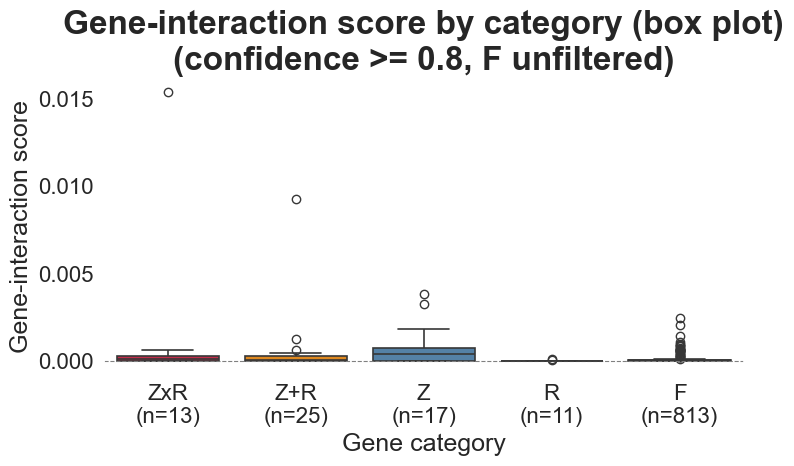

Mean cont_score per category (confidence >= 0.8):
category
ZxR    0.001330
Z+R    0.000552
Z      0.000782
R      0.000023
F      0.000065


In [25]:
# Same analysis as above, using box plots instead of violin plots
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=df_violin_conf, x='category', y='cont_score',
    order=cat_order, palette=cat_colors,
    linewidth=1.2, ax=ax,
)
ax.axhline(0, color='gray', lw=0.8, ls='--')
ax.set_xlabel('Gene category', fontsize=18)
ax.set_ylabel('Gene-interaction score', fontsize=18)
ax.set_title(
    f'Gene-interaction score by category (box plot)' + chr(10) +
    f'(confidence >= {CONF_THRESHOLD_VLN}, F unfiltered)',
    fontsize=24,
)
ax.set_xticklabels(
    [f'{c}' + chr(10) + f'(n={n_per_cat.get(c, 0)})' for c in cat_order], fontsize=16
)
plt.tight_layout()
plt.savefig(
    os.path.join(FIGURES_DIR, f'gene_cont_score_box_conf{CONF_THRESHOLD_VLN}.png'),
    dpi=150, bbox_inches='tight',
)
plt.show()

means = df_violin_conf.groupby('category')['cont_score'].mean().reindex(cat_order)
print(f'Mean cont_score per category (confidence >= {CONF_THRESHOLD_VLN}):')
print(means.to_string())


/tmp/ipykernel_339222/1295707102.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_339222/1295707102.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(
/tmp/ipykernel_339222/1295707102.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_339222/1295707102.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(


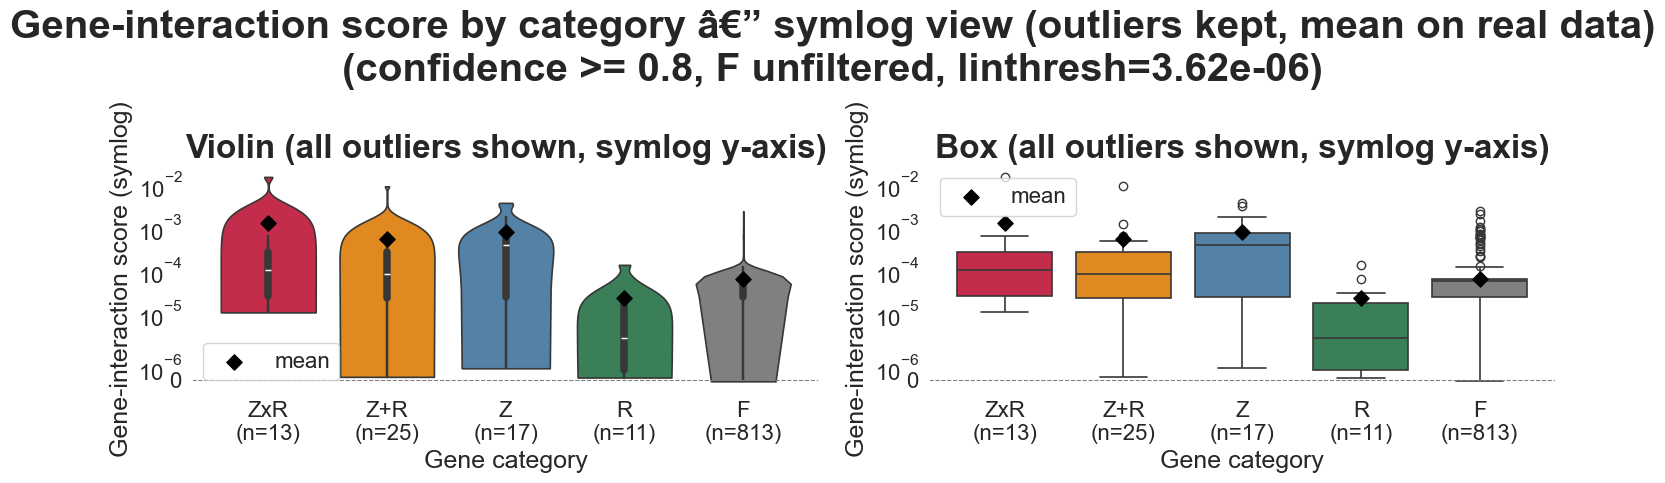

Mean cont_score per category (confidence >= 0.8, all outliers included):
category
ZxR    0.001330
Z+R    0.000552
Z      0.000782
R      0.000023
F      0.000065


In [26]:
# Same confidence-filtered distributions, all outliers kept, on a symlog y-axis
# (linear near zero, logarithmic further out) so extreme values don't swamp the
# plot while the mean is still computed on the full, untouched data.
abs_nonzero = df_violin_conf.loc[df_violin_conf['cont_score'] != 0, 'cont_score'].abs()
linthresh = max(abs_nonzero.quantile(0.1), 1e-6)
means = df_violin_conf.groupby('category')['cont_score'].mean().reindex(cat_order)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.violinplot(
    data=df_violin_conf, x='category', y='cont_score',
    order=cat_order, palette=cat_colors,
    inner='box', linewidth=1.2, ax=axes[0], cut=0,
)
axes[0].scatter(range(len(cat_order)), means.values, color='black', marker='D',
                 s=60, zorder=5, label='mean')
axes[0].set_yscale('symlog', linthresh=linthresh)
axes[0].axhline(0, color='gray', lw=0.8, ls='--')
axes[0].set_xlabel('Gene category', fontsize=18)
axes[0].set_ylabel('Gene-interaction score (symlog)', fontsize=18)
axes[0].set_title('Violin (all outliers shown, symlog y-axis)', fontsize=24)
axes[0].legend(loc='best', fontsize=16)
axes[0].set_xticklabels(
    [f'{c}' + chr(10) + f'(n={n_per_cat.get(c, 0)})' for c in cat_order], fontsize=16
)

sns.boxplot(
    data=df_violin_conf, x='category', y='cont_score',
    order=cat_order, palette=cat_colors,
    linewidth=1.2, ax=axes[1], showfliers=True,
)
axes[1].scatter(range(len(cat_order)), means.values, color='black', marker='D',
                 s=60, zorder=5, label='mean')
axes[1].set_yscale('symlog', linthresh=linthresh)
axes[1].axhline(0, color='gray', lw=0.8, ls='--')
axes[1].set_xlabel('Gene category', fontsize=18)
axes[1].set_ylabel('Gene-interaction score (symlog)', fontsize=18)
axes[1].set_title('Box (all outliers shown, symlog y-axis)', fontsize=24)
axes[1].legend(loc='best', fontsize=16)
axes[1].set_xticklabels(
    [f'{c}' + chr(10) + f'(n={n_per_cat.get(c, 0)})' for c in cat_order], fontsize=16
)

fig.suptitle(
    'Gene-interaction score by category â€” symlog view (outliers kept, mean on real data)' + chr(10) +
    f'(confidence >= {CONF_THRESHOLD_VLN}, F unfiltered, linthresh={linthresh:.3g})',
    fontsize=29,
)
plt.tight_layout()
plt.savefig(
    os.path.join(FIGURES_DIR, f'gene_cont_score_symlog_conf{CONF_THRESHOLD_VLN}.png'),
    dpi=150, bbox_inches='tight',
)
plt.show()

print(f'Mean cont_score per category (confidence >= {CONF_THRESHOLD_VLN}, all outliers included):')
print(means.to_string())


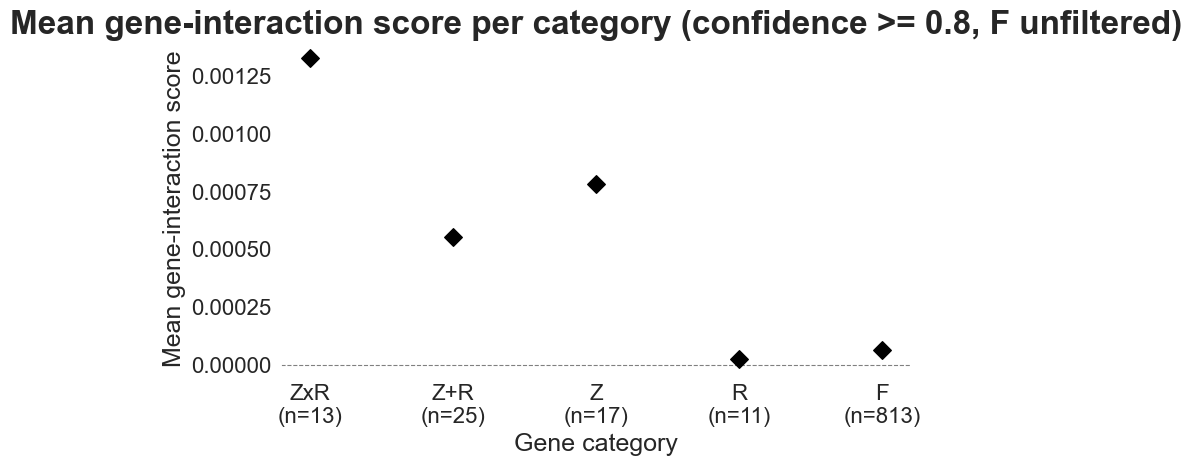

Mean cont_score per category (confidence >= 0.8):
category
ZxR    0.001330
Z+R    0.000552
Z      0.000782
R      0.000023
F      0.000065


In [27]:
# Same confidence-filtered group means as above, but showing only the mean marker
# (no violin/box distribution) -- just the black diamond per category.
means_only = df_violin_conf.groupby('category')['cont_score'].mean().reindex(cat_order)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(range(len(cat_order)), means_only.values, color='black', marker='D',
           s=80, zorder=5, label='mean')
ax.axhline(0, color='gray', lw=0.8, ls='--')
ax.set_xticks(range(len(cat_order)))
ax.set_xticklabels(
    [f'{c}' + chr(10) + f'(n={n_per_cat.get(c, 0)})' for c in cat_order], fontsize=16
)
ax.set_xlabel('Gene category', fontsize=18)
ax.set_ylabel('Mean gene-interaction score', fontsize=18)
ax.set_title(
    f'Mean gene-interaction score per category (confidence >= {CONF_THRESHOLD_VLN}, F unfiltered)',
    fontsize=24,
)
plt.tight_layout()
plt.savefig(
    os.path.join(FIGURES_DIR, f'gene_cont_score_mean_only_conf{CONF_THRESHOLD_VLN}.png'),
    dpi=150, bbox_inches='tight',
)
plt.show()

print(f'Mean cont_score per category (confidence >= {CONF_THRESHOLD_VLN}):')
print(means_only.to_string())
